In [1]:
import pandas as pd

In [ ]:
sample_df = pd.read_csv("../generated_data/timebin_identification/timebin_sample_df.csv")

C:\Users\yuyue\AppData\Local\Temp\ipykernel_17420\727627142.py:1: DtypeWarning: Columns (50,51,73,75,77,78) have mixed types. Specify dtype option on import or set low_memory=False.
  sample_df = pd.read_csv("D:/culture_king_project/is_culture_king/timebin_sample_df.csv")


In [8]:
print(sample_df.columns.tolist())


['id', 'window_start', 'window_end', 'gpt_id', 'created_at.users', 'description', 'location', 'protected', 'verified_type', 'username', 'public_metrics.followers_count', 'public_metrics.following_count', 'public_metrics.tweet_count', 'public_metrics.listed_count', 'public_metrics.like_count.users', 'public_metrics.media_count', 'entities.url.urls', 'entities.description.mentions', 'entities.description.hashtags', 'entities.description.urls', 'url', 'profile_image_url', 'most_recent_tweet_id', 'name', 'verified', 'pinned_tweet_id', 'id.tweets', 'created_at.tweets', 'entities.urls.subject_pool', 'entities.mentions.subject_pool', 'entities.annotations.subject_pool', 'entities.hashtags.subject_pool', 'sampling_tweet', 'conversation_id.subject_pool', 'lang.subject_pool', 'public_metrics.retweet_count.subject_pool', 'public_metrics.reply_count.subject_pool', 'public_metrics.like_count.tweets', 'public_metrics.quote_count.subject_pool', 'public_metrics.bookmark_count.subject_pool', 'public_me

In [16]:
cols_to_show = [
'clean...pool', 'clean...pool.date', 'clean...state_simple', 'in_window'
]


test_df = sample_df[cols_to_show].head()
test_df

,clean...pool,clean...pool.date,clean...state_simple,in_window
0,trad,2024-10-28T04:52:01Z,California,True
1,trad,2024-10-28T04:52:01Z,California,True
2,trad,2024-10-28T04:52:01Z,California,True
3,trad,2024-10-28T04:52:01Z,California,True
4,trad,2024-10-28T04:52:01Z,California,True


In [16]:
sample_df["clean...pool"].unique()


array(['trad', 'protectionism', 'health', 'immigration', 'frees speech',
       'drugs', 'democracy', 'woke', 'radical', 'foreign policy', 'guns',
       'economy', 'media', 'crime', 'climate', 'race', 'discourse'],
      dtype=object)

In [17]:
import pandas as pd

window_counts = sample_df.groupby(['id', 'window_start', 'window_end']).size().reset_index(name='tweet_count')

def map_density(count):
    if count <= 5:
        return 'sparse'
    elif count <= 30:
        return 'medium'
    else:
        return 'rich'

window_counts['density'] = window_counts['tweet_count'].apply(map_density)

sample_df = sample_df.merge(
    window_counts[['id', 'window_start', 'window_end', 'density']],
    on=['id', 'window_start', 'window_end'],
    how='left'
)

print(sample_df[['id', 'window_start', 'window_end', 'density']].head(10))


         id               window_start                 window_end density
0  12695752  2024-02-22 00:00:00+00:00  2024-03-06 00:00:00+00:00  medium
1  12695752  2024-02-22 00:00:00+00:00  2024-03-06 00:00:00+00:00  medium
2  12695752  2024-02-22 00:00:00+00:00  2024-03-06 00:00:00+00:00  medium
3  12695752  2024-02-22 00:00:00+00:00  2024-03-06 00:00:00+00:00  medium
4  12695752  2024-02-22 00:00:00+00:00  2024-03-06 00:00:00+00:00  medium
5  12695752  2024-02-22 00:00:00+00:00  2024-03-06 00:00:00+00:00  medium
6  12695752  2024-02-22 00:00:00+00:00  2024-03-06 00:00:00+00:00  medium
7  12695752  2024-02-22 00:00:00+00:00  2024-03-06 00:00:00+00:00  medium
8  12695752  2024-02-22 00:00:00+00:00  2024-03-06 00:00:00+00:00  medium
9  12695752  2024-02-22 00:00:00+00:00  2024-03-06 00:00:00+00:00  medium


In [5]:
sample_df

,id,window_start,window_end,gpt_id,created_at.users,description,location,protected,verified_type,username,...,"gpt_speculation_QUOTA_IDEOLOGICALLY, THIS PERSON APPEARS TO BE",gpt_speculation_QUOTA_PAST VOTE - TURNOUT IN THE 2020 PRESIDENTIAL ELECTION,gpt_speculation_QUOTA_PAST VOTE - TURNOUT IN THE 2022 HOUSE OF REPRESENTATIVES ELECTION,gpt_speculation_QUOTA_PAST VOTE - VOTE CHOICE IN THE 2020 PRESIDENTIAL ELECTION,gpt_speculation_QUOTA_PAST VOTE - VOTE CHOICE IN THE 2022 HOUSE OF REPRESENTATIVES ELECTION,clean...pool,clean...pool.date,clean...state_simple,in_window,density
0,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,1f0dd719b37defb1e8184ffdd81cbc9cf6320d90a99451...,2008-01-25T20:19:58.000Z,Dantooine. They're on Dantooine.,Silicon Valley,False,none,dcurtisj,...,65,50.0,60,90,90,trad,2024-10-28T04:52:01Z,California,True,medium
1,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,1f0dd719b37defb1e8184ffdd81cbc9cf6320d90a99451...,2008-01-25T20:19:58.000Z,Dantooine. They're on Dantooine.,Silicon Valley,False,none,dcurtisj,...,65,50.0,60,90,90,trad,2024-10-28T04:52:01Z,California,True,medium
2,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,1f0dd719b37defb1e8184ffdd81cbc9cf6320d90a99451...,2008-01-25T20:19:58.000Z,Dantooine. They're on Dantooine.,Silicon Valley,False,none,dcurtisj,...,65,50.0,60,90,90,trad,2024-10-28T04:52:01Z,California,True,medium
3,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,1f0dd719b37defb1e8184ffdd81cbc9cf6320d90a99451...,2008-01-25T20:19:58.000Z,Dantooine. They're on Dantooine.,Silicon Valley,False,none,dcurtisj,...,65,50.0,60,90,90,trad,2024-10-28T04:52:01Z,California,True,medium
4,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,1f0dd719b37defb1e8184ffdd81cbc9cf6320d90a99451...,2008-01-25T20:19:58.000Z,Dantooine. They're on Dantooine.,Silicon Valley,False,none,dcurtisj,...,65,50.0,60,90,90,trad,2024-10-28T04:52:01Z,California,True,medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40058,1839135745908305920,2023-12-20 00:00:00+00:00,2024-01-02 00:00:00+00:00,ceb7343944dc0fe98c9abea2841b14bd4df3d5b00aaf01...,2024-09-26T02:51:46.000Z,Foodie,USA,False,none,highway_vessel,...,50,60.0,60,50,60,democracy,2024-09-29T08:58:25Z,USA,False,sparse
40059,1839135745908305920,2024-05-04 00:00:00+00:00,2024-05-17 00:00:00+00:00,ceb7343944dc0fe98c9abea2841b14bd4df3d5b00aaf01...,2024-09-26T02:51:46.000Z,Foodie,USA,False,none,highway_vessel,...,50,60.0,60,50,60,democracy,2024-09-29T08:58:25Z,USA,False,sparse
40060,1839135745908305920,2024-09-01 00:00:00+00:00,2024-09-14 00:00:00+00:00,ceb7343944dc0fe98c9abea2841b14bd4df3d5b00aaf01...,2024-09-26T02:51:46.000Z,Foodie,USA,False,none,highway_vessel,...,50,60.0,60,50,60,democracy,2024-09-29T08:58:25Z,USA,False,sparse
40061,1839135745908305920,2024-09-24 00:00:00+00:00,2024-10-07 00:00:00+00:00,ceb7343944dc0fe98c9abea2841b14bd4df3d5b00aaf01...,2024-09-26T02:51:46.000Z,Foodie,USA,False,none,highway_vessel,...,50,60.0,60,50,60,democracy,2024-09-29T08:58:25Z,USA,True,sparse


In [18]:
avg_tweets = window_counts['tweet_count'].mean()
print(f"Average tweets per window: {avg_tweets:.2f}")


Average tweets per window: 64.62


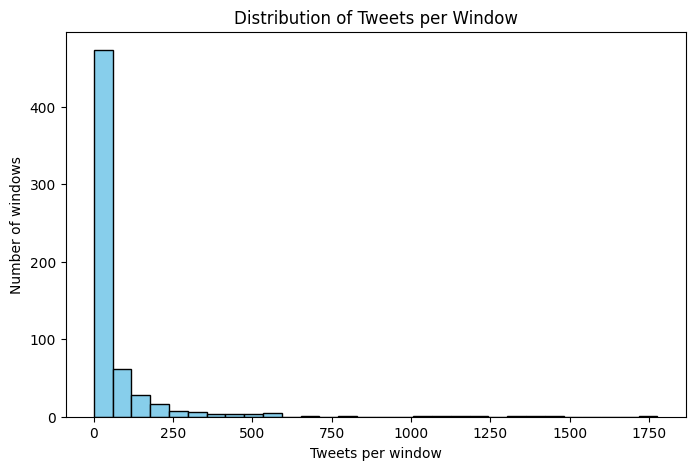

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(window_counts['tweet_count'], bins=30, color='skyblue', edgecolor='black')
plt.xlabel('Tweets per window')
plt.ylabel('Number of windows')
plt.title('Distribution of Tweets per Window')
plt.show()


In [8]:
window_counts

,id,window_start,window_end,tweet_count,density
0,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,20,medium
1,12695752,2024-07-05 00:00:00+00:00,2024-07-18 00:00:00+00:00,21,medium
2,12695752,2024-09-26 00:00:00+00:00,2024-10-09 00:00:00+00:00,4,sparse
3,12695752,2024-10-15 00:00:00+00:00,2024-10-28 00:00:00+00:00,19,medium
4,14728999,2023-11-19 00:00:00+00:00,2023-12-02 00:00:00+00:00,1,sparse
...,...,...,...,...,...
615,1834689413168672768,2024-08-12 00:00:00+00:00,2024-08-25 00:00:00+00:00,1,sparse
616,1839135745908305920,2023-12-20 00:00:00+00:00,2024-01-02 00:00:00+00:00,1,sparse
617,1839135745908305920,2024-05-04 00:00:00+00:00,2024-05-17 00:00:00+00:00,1,sparse
618,1839135745908305920,2024-09-01 00:00:00+00:00,2024-09-14 00:00:00+00:00,1,sparse


In [19]:
# Pick 2 rich, 2 medium and 2 sparse windows for the spot check
unique_windows = sample_df[['id', 'window_start', 'window_end', 'density', 'clean...pool']].drop_duplicates()
selected_windows = []

for density in ['sparse', 'medium', 'rich']:
    # Subset for this density
    subset = unique_windows[unique_windows['density'] == density].copy()
    
    # Keep track of topics already picked
    used_topics = set()
    samples = []
    
    for _, row in subset.sample(frac=1, random_state=42).iterrows():  # shuffle
        if row['clean...pool'] not in used_topics:
            samples.append(row)
            used_topics.add(row['clean...pool'])
        if len(samples) == 2:
            break
    
    selected_windows.extend(samples)

# Convert to DataFrame
selected_windows_df = pd.DataFrame(selected_windows)

selected_windows_df


,id,window_start,window_end,density,clean...pool
37466,1726109990954668032,2024-06-18 00:00:00+00:00,2024-07-01 00:00:00+00:00,sparse,race
4543,32921295,2023-12-15 00:00:00+00:00,2023-12-28 00:00:00+00:00,sparse,democracy
0,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,medium,trad
5031,39699931,2024-07-12 00:00:00+00:00,2024-07-25 00:00:00+00:00,medium,guns
36482,1715552550806749184,2024-03-30 00:00:00+00:00,2024-04-12 00:00:00+00:00,rich,race
37137,1718085102452817920,2024-10-03 00:00:00+00:00,2024-10-16 00:00:00+00:00,rich,discourse


In [20]:
spot_check_df = sample_df.merge(
    selected_windows_df[['id', 'window_start', 'window_end']],
    on=['id', 'window_start', 'window_end'],
    how='inner'
)

In [21]:
spot_check_df

,id,window_start,window_end,gpt_id,created_at.users,description,location,protected,verified_type,username,...,"gpt_speculation_QUOTA_IDEOLOGICALLY, THIS PERSON APPEARS TO BE",gpt_speculation_QUOTA_PAST VOTE - TURNOUT IN THE 2020 PRESIDENTIAL ELECTION,gpt_speculation_QUOTA_PAST VOTE - TURNOUT IN THE 2022 HOUSE OF REPRESENTATIVES ELECTION,gpt_speculation_QUOTA_PAST VOTE - VOTE CHOICE IN THE 2020 PRESIDENTIAL ELECTION,gpt_speculation_QUOTA_PAST VOTE - VOTE CHOICE IN THE 2022 HOUSE OF REPRESENTATIVES ELECTION,clean...pool,clean...pool.date,clean...state_simple,in_window,density
0,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,1f0dd719b37defb1e8184ffdd81cbc9cf6320d90a99451...,2008-01-25T20:19:58.000Z,Dantooine. They're on Dantooine.,Silicon Valley,False,none,dcurtisj,...,65,50.0,60,90,90,trad,2024-10-28T04:52:01Z,California,True,medium
1,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,1f0dd719b37defb1e8184ffdd81cbc9cf6320d90a99451...,2008-01-25T20:19:58.000Z,Dantooine. They're on Dantooine.,Silicon Valley,False,none,dcurtisj,...,65,50.0,60,90,90,trad,2024-10-28T04:52:01Z,California,True,medium
2,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,1f0dd719b37defb1e8184ffdd81cbc9cf6320d90a99451...,2008-01-25T20:19:58.000Z,Dantooine. They're on Dantooine.,Silicon Valley,False,none,dcurtisj,...,65,50.0,60,90,90,trad,2024-10-28T04:52:01Z,California,True,medium
3,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,1f0dd719b37defb1e8184ffdd81cbc9cf6320d90a99451...,2008-01-25T20:19:58.000Z,Dantooine. They're on Dantooine.,Silicon Valley,False,none,dcurtisj,...,65,50.0,60,90,90,trad,2024-10-28T04:52:01Z,California,True,medium
4,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,1f0dd719b37defb1e8184ffdd81cbc9cf6320d90a99451...,2008-01-25T20:19:58.000Z,Dantooine. They're on Dantooine.,Silicon Valley,False,none,dcurtisj,...,65,50.0,60,90,90,trad,2024-10-28T04:52:01Z,California,True,medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
447,1718085102452817920,2024-10-03 00:00:00+00:00,2024-10-16 00:00:00+00:00,626e582f0538219b1b8bbebc8db3f6dde5bef835227b91...,2023-10-28T02:00:06.000Z,Stocks & Sports,"Queens, NY",False,none,RP3onX,...,70,80.0,90,90,90,discourse,2024-10-15T05:19:52Z,New York,True,rich
448,1726109990954668032,2024-06-18 00:00:00+00:00,2024-07-01 00:00:00+00:00,4d17c55563c7861b35d97b9eb41bc6b5b76691ca37cead...,2023-11-19T05:28:00.000Z,#Bitcoin | $MSTR $TSLA $MARA $RIOT Investor | ...,"Washington, DC",False,blue,tarikjpierce,...,40,40.0,40,30,50,race,2024-10-15T05:32:12Z,District of Columbia,True,sparse
449,1726109990954668032,2024-06-18 00:00:00+00:00,2024-07-01 00:00:00+00:00,4d17c55563c7861b35d97b9eb41bc6b5b76691ca37cead...,2023-11-19T05:28:00.000Z,#Bitcoin | $MSTR $TSLA $MARA $RIOT Investor | ...,"Washington, DC",False,blue,tarikjpierce,...,40,40.0,40,30,50,race,2024-10-15T05:32:12Z,District of Columbia,True,sparse
450,1726109990954668032,2024-06-18 00:00:00+00:00,2024-07-01 00:00:00+00:00,4d17c55563c7861b35d97b9eb41bc6b5b76691ca37cead...,2023-11-19T05:28:00.000Z,#Bitcoin | $MSTR $TSLA $MARA $RIOT Investor | ...,"Washington, DC",False,blue,tarikjpierce,...,40,40.0,40,30,50,race,2024-10-15T05:32:12Z,District of Columbia,True,sparse


In [22]:
tweet_counts_per_window = (
    spot_check_df
    .groupby(['id', 'window_start', 'window_end'])
    .size()
    .reset_index(name='tweet_count')
)

tweet_counts_per_window


,id,window_start,window_end,tweet_count
0,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,20
1,32921295,2023-12-15 00:00:00+00:00,2023-12-28 00:00:00+00:00,1
2,39699931,2024-07-12 00:00:00+00:00,2024-07-25 00:00:00+00:00,12
3,1715552550806749184,2024-03-30 00:00:00+00:00,2024-04-12 00:00:00+00:00,88
4,1718085102452817920,2024-10-03 00:00:00+00:00,2024-10-16 00:00:00+00:00,327
5,1726109990954668032,2024-06-18 00:00:00+00:00,2024-07-01 00:00:00+00:00,4


In [23]:
test_df = spot_check_df[['description', 'name', 'username','location','clean...pool','public_metrics.followers_count', 'created_at', 'tweets_historical']]
test_df

,description,name,username,location,clean...pool,public_metrics.followers_count,created_at,tweets_historical
0,Dantooine. They're on Dantooine.,Dan Curtis Johnson,dcurtisj,Silicon Valley,trad,1249,2024-03-05 22:58:24+00:00,@TheStalwart It's a good thing you never troll...
1,Dantooine. They're on Dantooine.,Dan Curtis Johnson,dcurtisj,Silicon Valley,trad,1249,2024-03-05 06:15:59+00:00,@midjourney Wordle 989 3/6*\n\n⬜🟨⬜⬜🟩\n⬜🟩🟩⬜🟩\n🟩...
2,Dantooine. They're on Dantooine.,Dan Curtis Johnson,dcurtisj,Silicon Valley,trad,1249,2024-03-04 14:58:11+00:00,More people finding the courage of their convi...
3,Dantooine. They're on Dantooine.,Dan Curtis Johnson,dcurtisj,Silicon Valley,trad,1249,2024-03-04 03:34:25+00:00,@midjourney Wordle 988 5/6*\n\n⬜🟨⬜🟨🟩\n🟩🟩🟩⬜🟩\n🟩...
4,Dantooine. They're on Dantooine.,Dan Curtis Johnson,dcurtisj,Silicon Valley,trad,1249,2024-03-03 03:09:41+00:00,@midjourney Wordle 987 4/6*\n\n🟨🟨⬜⬜⬜\n⬜⬜🟨🟨⬜\n🟨...
...,...,...,...,...,...,...,...,...
447,Stocks & Sports,RP3,RP3onX,"Queens, NY",discourse,727,2024-10-03 01:12:23+00:00,@TMathSports @DKSportsbook @DraftKings This is...
448,#Bitcoin | $MSTR $TSLA $MARA $RIOT Investor | ...,Tarik Pierce,tarikjpierce,"Washington, DC",race,737,2024-06-21 04:51:59+00:00,Sell Nvidia $NVDA #inversecramer https://t.co/...
449,#Bitcoin | $MSTR $TSLA $MARA $RIOT Investor | ...,Tarik Pierce,tarikjpierce,"Washington, DC",race,737,2024-06-18 11:07:11+00:00,@SawyerMerritt Such a scam
450,#Bitcoin | $MSTR $TSLA $MARA $RIOT Investor | ...,Tarik Pierce,tarikjpierce,"Washington, DC",race,737,2024-06-18 08:17:41+00:00,@Rothmus Pathetic western men


In [24]:
import pandas as pd

# Election date as naive
election_date = pd.to_datetime("2024-11-05")

# Function to make datetime naive (remove timezone)
def make_naive(dt):
    if pd.isna(dt):
        return dt
    if dt.tzinfo is not None:
        return dt.tz_convert(None) if hasattr(dt, 'tz_convert') else dt.replace(tzinfo=None)
    return dt

# Apply to tweets
spot_check_df['tweets_struct'] = spot_check_df.apply(
    lambda row: {
        'text': row['tweets_historical'],
        'created_at': make_naive(pd.to_datetime(row['created_at'])),
        'days_to_election': (election_date - make_naive(pd.to_datetime(row['created_at']))).days
    },
    axis=1
)

# Then group by window
window_profiles = (
    spot_check_df
    .groupby(['id', 'window_start', 'window_end'])
    .agg({
        'name': 'first',
        'username': 'first',
        'description': 'first',
        'location': 'first',
        'public_metrics.followers_count': 'first',
        'clean...pool': 'first',  
        'tweets_struct': list
    })
    .reset_index()
)


In [25]:
window_profiles

,id,window_start,window_end,name,username,description,location,public_metrics.followers_count,clean...pool,tweets_struct
0,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,Dan Curtis Johnson,dcurtisj,Dantooine. They're on Dantooine.,Silicon Valley,1249,trad,[{'text': '@TheStalwart It's a good thing you ...
1,32921295,2023-12-15 00:00:00+00:00,2023-12-28 00:00:00+00:00,KamalaisTHATgirl,lynetteware50,"WOKE #Mompreuner of 3 | GiGi of 1, #PowerMom #...",Chicago,1866,democracy,[{'text': '@keithboykin thank you brother. Don...
2,39699931,2024-07-12 00:00:00+00:00,2024-07-25 00:00:00+00:00,SpoopyRuen,ShreddingRuen,34. He/Him. Aspiring Writer. Straight Edge. De...,MA,457,guns,"[{'text': '@iamBrandonTV Legend of Dragoon, an..."
3,1715552550806749184,2024-03-30 00:00:00+00:00,2024-04-12 00:00:00+00:00,Delameter,Delam46,"Strong Christian morals and values, with conse...",Montana,151,race,"[{'text': 'https://t.co/jtrMPOakyu', 'created_..."
4,1718085102452817920,2024-10-03 00:00:00+00:00,2024-10-16 00:00:00+00:00,RP3,RP3onX,Stocks & Sports,"Queens, NY",727,discourse,[{'text': '@dotkrueger Cointards in 2017: Ban...
5,1726109990954668032,2024-06-18 00:00:00+00:00,2024-07-01 00:00:00+00:00,Tarik Pierce,tarikjpierce,#Bitcoin | $MSTR $TSLA $MARA $RIOT Investor | ...,"Washington, DC",737,race,[{'text': 'Sell Nvidia $NVDA #inversecramer ht...


In [27]:
print(type(window_profiles['tweets_struct']))

<class 'pandas.core.series.Series'>


In [26]:
print(window_profiles['tweets_struct'].iloc[0])

[{'text': "@TheStalwart It's a good thing you never troll or there would be real trouble.", 'created_at': Timestamp('2024-03-05 22:58:24'), 'days_to_election': 244}, {'text': '@midjourney Wordle 989 3/6*\n\n⬜🟨⬜⬜🟩\n⬜🟩🟩⬜🟩\n🟩🟩🟩🟩🟩 https://t.co/k4KEjmEbjU', 'created_at': Timestamp('2024-03-05 06:15:59'), 'days_to_election': 244}, {'text': "More people finding the courage of their convictions only after it's no longer particularly courageous and it's too late to get a conviction. https://t.co/jyErHO0O8T", 'created_at': Timestamp('2024-03-04 14:58:11'), 'days_to_election': 245}, {'text': '@midjourney Wordle 988 5/6*\n\n⬜🟨⬜🟨🟩\n🟩🟩🟩⬜🟩\n🟩🟩🟩⬜🟩\n🟩🟩🟩⬜🟩\n🟩🟩🟩🟩🟩 https://t.co/zyrMh1RGFT', 'created_at': Timestamp('2024-03-04 03:34:25'), 'days_to_election': 245}, {'text': '@midjourney Wordle 987 4/6*\n\n🟨🟨⬜⬜⬜\n⬜⬜🟨🟨⬜\n🟨🟩⬜🟩⬜\n🟩🟩🟩🟩🟩 https://t.co/I1jrlkdrXG', 'created_at': Timestamp('2024-03-03 03:09:41'), 'days_to_election': 246}, {'text': '@midjourney Wordle 986 3/6*\n\n🟨⬜⬜⬜⬜\n🟩🟩🟩🟩⬜\n🟩🟩🟩🟩🟩 https://t.co/OXHz

In [ ]:
window_profiles.to_csv("../generated_data/timebin_identification/14days_window/new_window_profiles.csv", index=False)

In [29]:
import ast 
window_profiles["tweet_count"] = window_profiles["tweets_struct"].apply(len)

In [30]:
window_profiles

,id,window_start,window_end,name,username,description,location,public_metrics.followers_count,clean...pool,tweets_struct,tweet_count
0,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,Dan Curtis Johnson,dcurtisj,Dantooine. They're on Dantooine.,Silicon Valley,1249,trad,[{'text': '@TheStalwart It's a good thing you ...,20
1,32921295,2023-12-15 00:00:00+00:00,2023-12-28 00:00:00+00:00,KamalaisTHATgirl,lynetteware50,"WOKE #Mompreuner of 3 | GiGi of 1, #PowerMom #...",Chicago,1866,democracy,[{'text': '@keithboykin thank you brother. Don...,1
2,39699931,2024-07-12 00:00:00+00:00,2024-07-25 00:00:00+00:00,SpoopyRuen,ShreddingRuen,34. He/Him. Aspiring Writer. Straight Edge. De...,MA,457,guns,"[{'text': '@iamBrandonTV Legend of Dragoon, an...",12
3,1715552550806749184,2024-03-30 00:00:00+00:00,2024-04-12 00:00:00+00:00,Delameter,Delam46,"Strong Christian morals and values, with conse...",Montana,151,race,"[{'text': 'https://t.co/jtrMPOakyu', 'created_...",88
4,1718085102452817920,2024-10-03 00:00:00+00:00,2024-10-16 00:00:00+00:00,RP3,RP3onX,Stocks & Sports,"Queens, NY",727,discourse,[{'text': '@dotkrueger Cointards in 2017: Ban...,327
5,1726109990954668032,2024-06-18 00:00:00+00:00,2024-07-01 00:00:00+00:00,Tarik Pierce,tarikjpierce,#Bitcoin | $MSTR $TSLA $MARA $RIOT Investor | ...,"Washington, DC",737,race,[{'text': 'Sell Nvidia $NVDA #inversecramer ht...,4


In [ ]:
import pandas as pd
window_profiles = pd.read_csv("../generated_data/timebin_identification/14days_window/new_window_profiles.csv")

In [10]:
window_profiles

,id,window_start,window_end,name,username,description,location,public_metrics.followers_count,clean...pool,tweets_struct,tweet_count
0,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,Dan Curtis Johnson,dcurtisj,Dantooine. They're on Dantooine.,Silicon Valley,1249,trad,"[{'text': ""@TheStalwart It's a good thing you ...",20
1,32921295,2023-12-15 00:00:00+00:00,2023-12-28 00:00:00+00:00,KamalaisTHATgirl,lynetteware50,"WOKE #Mompreuner of 3 | GiGi of 1, #PowerMom #...",Chicago,1866,democracy,[{'text': '@keithboykin thank you brother. Don...,1
2,39699931,2024-07-12 00:00:00+00:00,2024-07-25 00:00:00+00:00,SpoopyRuen,ShreddingRuen,34. He/Him. Aspiring Writer. Straight Edge. De...,MA,457,guns,"[{'text': '@iamBrandonTV Legend of Dragoon, an...",12
3,1715552550806749184,2024-03-30 00:00:00+00:00,2024-04-12 00:00:00+00:00,Delameter,Delam46,"Strong Christian morals and values, with conse...",Montana,151,race,"[{'text': 'https://t.co/jtrMPOakyu', 'created_...",88
4,1718085102452817920,2024-10-03 00:00:00+00:00,2024-10-16 00:00:00+00:00,RP3,RP3onX,Stocks & Sports,"Queens, NY",727,discourse,[{'text': '@dotkrueger Cointards in 2017: Ban...,327
5,1726109990954668032,2024-06-18 00:00:00+00:00,2024-07-01 00:00:00+00:00,Tarik Pierce,tarikjpierce,#Bitcoin | $MSTR $TSLA $MARA $RIOT Investor | ...,"Washington, DC",737,race,[{'text': 'Sell Nvidia $NVDA #inversecramer ht...,4


In [3]:
test_profile = window_profiles.iloc[[0]].copy()

In [4]:
test_profile

,id,window_start,window_end,name,username,description,location,public_metrics.followers_count,clean...pool,tweets_struct,tweet_count
0,12695752,2024-02-22 00:00:00+00:00,2024-03-06 00:00:00+00:00,Dan Curtis Johnson,dcurtisj,Dantooine. They're on Dantooine.,Silicon Valley,1249,trad,"[{'text': ""@TheStalwart It's a good thing you ...",20


In [5]:
rich_test_profile = window_profiles.iloc[[3]].copy()

In [6]:
rich_test_profile

,id,window_start,window_end,name,username,description,location,public_metrics.followers_count,clean...pool,tweets_struct,tweet_count
3,1715552550806749184,2024-03-30 00:00:00+00:00,2024-04-12 00:00:00+00:00,Delameter,Delam46,"Strong Christian morals and values, with conse...",Montana,151,race,"[{'text': 'https://t.co/jtrMPOakyu', 'created_...",88


In [7]:
very_rich_test_profile = window_profiles.iloc[[4]].copy()

In [8]:
very_rich_test_profile 

,id,window_start,window_end,name,username,description,location,public_metrics.followers_count,clean...pool,tweets_struct,tweet_count
4,1718085102452817920,2024-10-03 00:00:00+00:00,2024-10-16 00:00:00+00:00,RP3,RP3onX,Stocks & Sports,"Queens, NY",727,discourse,[{'text': '@dotkrueger Cointards in 2017: Ban...,327


In [9]:
sparse_test_profile = window_profiles.iloc[[5]].copy()

In [10]:
sparse_test_profile

,id,window_start,window_end,name,username,description,location,public_metrics.followers_count,clean...pool,tweets_struct,tweet_count
5,1726109990954668032,2024-06-18 00:00:00+00:00,2024-07-01 00:00:00+00:00,Tarik Pierce,tarikjpierce,#Bitcoin | $MSTR $TSLA $MARA $RIOT Investor | ...,"Washington, DC",737,race,[{'text': 'Sell Nvidia $NVDA #inversecramer ht...,4


In [ ]:
#First window medium tweet density (20 tweets in the given window), trad topic, divorce + Israel/Hamas war
import os
import requests
import json
import time
import re

# ------------------------------------------------------------
# 1. Endpoint & authentication
# ------------------------------------------------------------
endpoint_base = "https://aipolling.services.ai.azure.com/models"
api_version = "2024-05-01-preview"
url = f"{endpoint_base}/chat/completions?api-version={api_version}"

# Load API key from environment variable
api_key = os.getenv("AZURE_API_KEY")
if not api_key:
    raise ValueError("AZURE_API_KEY environment variable is not set")

# ------------------------------------------------------------
# Function to infer beliefs for one user window
# ------------------------------------------------------------
prompt_template = """
**User Profile:**
- Name: {name}
- Username: {username}
- Bio: {description}
- Location: {location}
- Followers: {followers}
- Tweets in this time window: {tweets}

I will show you a number of categories to which this user may belong to.
The categories are preceded by a title (e.g. "AGE:" or "SEX:" etc.) and a symbol (e.g. "A1", "A2" or "E1" etc.).
For each of the titles below, you must select the most likely category the user belongs to. In your answer present, for each title, the selected symbol.
Write out in full the category associated with the selected symbol.
The chosen symbol / category must be the most likely to accurately represent this user.
You must only select one symbol / category per title.
A title, symbol and category cannot appear more than once in your answer.
Please select the category following the given steps.

*Step 1: From the provided user data, extract any information directly or indirectly related to the title's topic. 
*Step 2: From the extracted information, understand the contextual information, which includes the topic of the text, the identity of the author, the target audience, and the relevant socio-cultural background
*Step 3: Analyze the core viewpoints and main intentions to be expressed in the extracted information.
*Step 4: Analyze the language expression and emotional inclination of the extracted information. Identify the emotional words and rhetorical devices used within the text, and analyze the tone adopted by the author (e.g., affirmative, negative, interrogative, exclamatory, etc.). Based on this analysis, describe the author’s emotional attitude.
*Step 5: Compare similarities and contrasts between the analyzed information and each of the provided categories for the title, based on the above-mentioned information.
*Step 6: Conduct logical inference based on the context and other relevant information to confirm the consistency and rationality of the selected category.
*Step 7: Based on the above information, determine the final selected category.
*Step 8:
For each selected symbol/category, please note the level of Speculation involved in this selection.
Present the Speculation level for each selection on a scale from 0 (not speculative at all, every single element of the user data was useful in the selection) to 100 (fully speculative, there is no information related to this title in the user data).
Speculation levels should be a direct measure of the amount of useful information available in the user data.
Speculation levels pertain only to the information available in the user data -- namely the username, name, description, location, profile picture and tweets from this user -- and should not be affected by additional information available to you from any other source.

To ensure consistency, use the following guidelines to determine speculation levels:

0-20 (Low speculation): The user data provides clear and direct information relevant to the title. (e.g., explicit mention in the profile or tweets)
21-40 (Moderate-low speculation): The user data provides indirect but strong indicators relevant to the title.
41-60 (Moderate speculation): The user data provides some hints or partial information relevant to the title.
61-80 (Moderate-high speculation): The user data provides limited and weak indicators relevant to the title.
81-100 (High speculation): The user data provides no or almost no information relevant to the title.

Step 9: For each selected symbol/category, please give a concise summary of Steps 1-8. Explain at length what features of the data contributed to your choice and your speculation level.

Preserve a strictly structured answer to ease parsing of the text.
Format your output as follows (this is just an example):

**title: AGE**
**explanation: ...**
**symbol: A1)**
**category: 18-25**
**speculation: 90**

YOU MUST GIVE AN ANSWER FOR EVERY TITLE !

Below is the list of categories to which this user may belong to:
- **OPINION ON WHETHER DIVORCE IN THE USA SHOULD BE EASIER OR MORE DIFFICULT TO OBTAIN THAN IT IS: ** 
    Choose one: [
    SoA1) Obtaining a divorce should be easier than it is, 
    SoA2) Obtaining a divorce should be more difficult than it is, 
    SoA3) Obtaining a divorce is the right level of difficulty as it is]  
- **OPINION ON WHICH SIDE HAS MORE VALID REASONS IN THE ISRAEL-HAMAS WAR:** 
    Choose one: [
    IsA1) Israel has much more valid reasons for waging war against Hamas than Hamas has for waging war against Israel, 
    IsA2) Israel has somewhat more valid reasons for waging war against Hamas than Hamas has for waging war against Israel, 
    IsA3) Israel's reasons for waging war against Hamas and Hamas' reasons for waging war against Israel are equally valid, 
    IsA4) Hamas has somewhat more valid reasons for waging war against Israel than Israel has for waging war against Hamas, 
    IsA5) Hamas has much more valid reasons for waging war against Israel than Israel has for waging war against Hamas]

    """
# ----------------------------
# Belief Parsing Function
# ----------------------------
def parse_belief_response(response):
        categories = {
            "Belief_Divorce_Category": None,
            "Belief_IsraelHamas_Category": None
        }
        explanations = {
            "Belief_Divorce_Explanation": None,
            "Belief_IsraelHamas_Explanation": None
        }
        speculations = {
            "Belief_Divorce_Speculation": None,
            "Belief_IsraelHamas_Speculation": None
        }

        pattern = r"\*\*title: (.*?)\*\*\s*\*\*explanation:\**(.*?)\s*\*\*symbol: .*?\*\*\s*\*\*category: (.*?)\*\*\s*\*\*speculation: (\d+)\*\*"
        matches = re.findall(pattern, str(response), re.DOTALL)

        for title, explanation, category, speculation in matches:
            title_clean = title.strip().lower()
            if "divorce" in title_clean:
                categories["Belief_Divorce_Category"] = category.strip()
                explanations["Belief_Divorce_Explanation"] = explanation.strip()
                speculations["Belief_Divorce_Speculation"] = speculation.strip()
            elif "israel" in title_clean or "hamas" in title_clean:
                categories["Belief_IsraelHamas_Category"] = category.strip()
                explanations["Belief_IsraelHamas_Explanation"] = explanation.strip()
                speculations["Belief_IsraelHamas_Speculation"] = speculation.strip()

        return {**categories, **explanations, **speculations}


# ------------------------------------------------------------
# 2. Build the request body
# ------------------------------------------------------------
def infer_beliefs(row, model_name):

    prompt = prompt_template.format(
        name=row['name'],
        username=row['username'],
        description=row['description'],
        location=row['location'],
        followers=row['public_metrics.followers_count'],
        tweets=row['tweets_struct']
    )

    messages = [
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": prompt}
    ]

    body = {
        "model": model_name,
        "max_tokens": 4096,
        "messages": messages
    }

    headers = {
        "Content-Type": "application/json",
        "api-key": api_key
    }

    response = requests.post(url, headers=headers, data=json.dumps(body))

    response.raise_for_status()

    content_json = response.json()
    reply = content_json["choices"][0]["message"]["content"]
    return reply

# ------------------------------------------------------------
# Apply inference to the window_profiles dataframe
# ------------------------------------------------------------
models = [
    "gpt-oss-120b"
]

df = test_profile
all_results = []

for model_name in models:
    for index, row in df.iterrows():
        try:
            belief_text = infer_beliefs(row, model_name)
            parsed_result = parse_belief_response(belief_text)

            combined_row = row.to_dict()
            combined_row.update({
                "Model": model_name,
                "Belief_Raw": belief_text
            })
            combined_row.update(parsed_result)
            all_results.append(combined_row)

            time.sleep(1)  
        except Exception as e:
            print(f"Error processing row {index} for model {model_name}: {e}")

final_df = pd.DataFrame(all_results)
final_df.to_csv("../generated_data/prompt_labeling/CoS_results/CoS_medium_beliefs_all_models_by_row.csv", index=False, encoding="utf-8-sig")
print("Done! CSV with one row per user × model created.")


Done! CSV with one row per user × model created.


In [ ]:
#Fourth window high tweet density (88 tweets in the given window), race topic, white people benefit + Israel/Hamas war
import os
import requests
import json
import time
import re

# ------------------------------------------------------------
# 1. Endpoint & authentication
# ------------------------------------------------------------
endpoint_base = "https://aipolling.services.ai.azure.com/models"
api_version = "2024-05-01-preview"
url = f"{endpoint_base}/chat/completions?api-version={api_version}"

# Load API key from environment variable
api_key = os.getenv("AZURE_API_KEY")
if not api_key:
    raise ValueError("AZURE_API_KEY environment variable is not set")

# ------------------------------------------------------------
# Function to infer beliefs for one user window
# ------------------------------------------------------------
prompt_template = """
**User Profile:**
- Name: {name}
- Username: {username}
- Bio: {description}
- Location: {location}
- Followers: {followers}
- Tweets in this time window: {tweets}

I will show you a number of categories to which this user may belong to.
The categories are preceded by a title (e.g. "AGE:" or "SEX:" etc.) and a symbol (e.g. "A1", "A2" or "E1" etc.).
For each of the titles below, you must select the most likely category the user belongs to. In your answer present, for each title, the selected symbol.
Write out in full the category associated with the selected symbol.
The chosen symbol / category must be the most likely to accurately represent this user.
You must only select one symbol / category per title.
A title, symbol and category cannot appear more than once in your answer.
Please select the category following the given steps.

*Step 1: From the provided user data, extract any information directly or indirectly related to the title's topic. 
*Step 2: From the extracted information, understand the contextual information, which includes the topic of the text, the identity of the author, the target audience, and the relevant socio-cultural background
*Step 3: Analyze the core viewpoints and main intentions to be expressed in the extracted information.
*Step 4: Analyze the language expression and emotional inclination of the extracted information. Identify the emotional words and rhetorical devices used within the text, and analyze the tone adopted by the author (e.g., affirmative, negative, interrogative, exclamatory, etc.). Based on this analysis, describe the author’s emotional attitude.
*Step 5: Compare similarities and contrasts between the analyzed information and each of the provided categories for the title, based on the above-mentioned information.
*Step 6: Conduct logical inference based on the context and other relevant information to confirm the consistency and rationality of the selected category.
*Step 7: Based on the above information, determine the final selected category.
*Step 8:
For each selected symbol/category, please note the level of Speculation involved in this selection.
Present the Speculation level for each selection on a scale from 0 (not speculative at all, every single element of the user data was useful in the selection) to 100 (fully speculative, there is no information related to this title in the user data).
Speculation levels should be a direct measure of the amount of useful information available in the user data.
Speculation levels pertain only to the information available in the user data -- namely the username, name, description, location, profile picture and tweets from this user -- and should not be affected by additional information available to you from any other source.

To ensure consistency, use the following guidelines to determine speculation levels:

0-20 (Low speculation): The user data provides clear and direct information relevant to the title. (e.g., explicit mention in the profile or tweets)
21-40 (Moderate-low speculation): The user data provides indirect but strong indicators relevant to the title.
41-60 (Moderate speculation): The user data provides some hints or partial information relevant to the title.
61-80 (Moderate-high speculation): The user data provides limited and weak indicators relevant to the title.
81-100 (High speculation): The user data provides no or almost no information relevant to the title.

Step 9: For each selected symbol/category, please give a concise summary of Steps 1-8. Explain at length what features of the data contributed to your choice and your speculation level.

Preserve a strictly structured answer to ease parsing of the text.
Format your output as follows (this is just an example):

**title: AGE**
**explanation: ...**
**symbol: A1)**
**category: 18-25**
**speculation: 90**

YOU MUST GIVE AN ANSWER FOR EVERY TITLE !

Below is the list of categories to which this user may belong to:
- **OPINION ON WHETHER WHITE PEOPLE BENEFIT FROM SOCIETAL ADVANTAGES NOT AVAILABLE TO BLACK PEOPLE : ** 
    Choose one: [
    RaA1) White people benefit a great deal from societal advantages not available to black people,
    RaA2) White people benefit a fair amount from societal advantages not available to black people,
    RaA3) White people benefit not too much from societal advantages not available to black people,
    RaA4) White people benefit not at all from societal advantages not available to black people]  
- **OPINION ON WHICH SIDE HAS MORE VALID REASONS IN THE ISRAEL-HAMAS WAR:** 
    Choose one: [
    IsA1) Israel has much more valid reasons for waging war against Hamas than Hamas has for waging war against Israel, 
    IsA2) Israel has somewhat more valid reasons for waging war against Hamas than Hamas has for waging war against Israel, 
    IsA3) Israel's reasons for waging war against Hamas and Hamas' reasons for waging war against Israel are equally valid, 
    IsA4) Hamas has somewhat more valid reasons for waging war against Israel than Israel has for waging war against Hamas, 
    IsA5) Hamas has much more valid reasons for waging war against Israel than Israel has for waging war against Hamas]

    """
# ----------------------------
# Belief Parsing Function
# ----------------------------
def parse_belief_response(response):
        categories = {
            "Belief_Whitebenefit_Category": None,
            "Belief_IsraelHamas_Category": None
        }
        explanations = {
            "Belief_Whitebenefit_Explanation": None,
            "Belief_IsraelHamas_Explanation": None
        }
        speculations = {
            "Belief_Whitebenefit_Speculation": None,
            "Belief_IsraelHamas_Speculation": None
        }

        pattern = r"\*\*title: (.*?)\*\*\s*\*\*explanation:\**(.*?)\s*\*\*symbol: .*?\*\*\s*\*\*category: (.*?)\*\*\s*\*\*speculation: (\d+)\*\*"
        matches = re.findall(pattern, str(response), re.DOTALL)

        for title, explanation, category, speculation in matches:
            title_clean = title.strip().lower()
            if "white" in title_clean:
                categories["Belief_Whitebenefit_Category"] = category.strip()
                explanations["Belief_Whitebenefit_Explanation"] = explanation.strip()
                speculations["Belief_Whitebenefit_Speculation"] = speculation.strip()
            elif "israel" in title_clean or "hamas" in title_clean:
                categories["Belief_IsraelHamas_Category"] = category.strip()
                explanations["Belief_IsraelHamas_Explanation"] = explanation.strip()
                speculations["Belief_IsraelHamas_Speculation"] = speculation.strip()

        return {**categories, **explanations, **speculations}


# ------------------------------------------------------------
# 2. Build the request body
# ------------------------------------------------------------
def infer_beliefs(row, model_name):

    prompt = prompt_template.format(
        name=row['name'],
        username=row['username'],
        description=row['description'],
        location=row['location'],
        followers=row['public_metrics.followers_count'],
        tweets=row['tweets_struct']
    )

    messages = [
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": prompt}
    ]

    body = {
        "model": model_name,
        "max_tokens": 4096,
        "messages": messages
    }

    headers = {
        "Content-Type": "application/json",
        "api-key": api_key
    }

    response = requests.post(url, headers=headers, data=json.dumps(body))

    response.raise_for_status()

    content_json = response.json()
    reply = content_json["choices"][0]["message"]["content"]
    return reply

# ------------------------------------------------------------
# Apply inference to the window_profiles dataframe
# ------------------------------------------------------------
models = [
    "gpt-oss-120b"
]

df = rich_test_profile
all_results = []

for model_name in models:
    for index, row in df.iterrows():
        try:
            belief_text = infer_beliefs(row, model_name)
            parsed_result = parse_belief_response(belief_text)

            combined_row = row.to_dict() 
            combined_row.update({
                "Model": model_name,
                "Belief_Raw": belief_text
            })
            combined_row.update(parsed_result)
            all_results.append(combined_row)

            time.sleep(1)  
        except Exception as e:
            print(f"Error processing row {index} for model {model_name}: {e}")

# Create a new DataFrame with one row per (user × model)
final_df = pd.DataFrame(all_results)
final_df.to_csv("../generated_data/prompt_labeling/CoS_results/CoS_rich_beliefs_all_models_by_row.csv", index=False, encoding="utf-8-sig")
print("Done! CSV with one row per user × model created.")

Done! CSV with one row per user × model created.


In [ ]:
#Fifth window with very high tweet density (327 tweets in the given window), discourse topic, political violence + Israel/Hamas war
import os
import requests
import json
import time
import re

# ------------------------------------------------------------
# 1. Endpoint & authentication
# ------------------------------------------------------------
endpoint_base = "https://aipolling.services.ai.azure.com/models"
api_version = "2024-05-01-preview"
url = f"{endpoint_base}/chat/completions?api-version={api_version}"

# Load API key from environment variable
api_key = os.getenv("AZURE_API_KEY")
if not api_key:
    raise ValueError("AZURE_API_KEY environment variable is not set")

# ------------------------------------------------------------
# Function to infer beliefs for one user window
# ------------------------------------------------------------
prompt_template = """
**User Profile:**
- Name: {name}
- Username: {username}
- Bio: {description}
- Location: {location}
- Followers: {followers}
- Tweets in this time window: {tweets}

I will show you a number of categories to which this user may belong to.
The categories are preceded by a title (e.g. "AGE:" or "SEX:" etc.) and a symbol (e.g. "A1", "A2" or "E1" etc.).
For each of the titles below, you must select the most likely category the user belongs to. In your answer present, for each title, the selected symbol.
Write out in full the category associated with the selected symbol.
The chosen symbol / category must be the most likely to accurately represent this user.
You must only select one symbol / category per title.
A title, symbol and category cannot appear more than once in your answer.
Please select the category following the given steps.

*Step 1: From the provided user data, extract any information directly or indirectly related to the title's topic. 
*Step 2: From the extracted information, understand the contextual information, which includes the topic of the text, the identity of the author, the target audience, and the relevant socio-cultural background
*Step 3: Analyze the core viewpoints and main intentions to be expressed in the extracted information.
*Step 4: Analyze the language expression and emotional inclination of the extracted information. Identify the emotional words and rhetorical devices used within the text, and analyze the tone adopted by the author (e.g., affirmative, negative, interrogative, exclamatory, etc.). Based on this analysis, describe the author’s emotional attitude.
*Step 5: Compare similarities and contrasts between the analyzed information and each of the provided categories for the title, based on the above-mentioned information.
*Step 6: Conduct logical inference based on the context and other relevant information to confirm the consistency and rationality of the selected category.
*Step 7: Based on the above information, determine the final selected category.
*Step 8:
For each selected symbol/category, please note the level of Speculation involved in this selection.
Present the Speculation level for each selection on a scale from 0 (not speculative at all, every single element of the user data was useful in the selection) to 100 (fully speculative, there is no information related to this title in the user data).
Speculation levels should be a direct measure of the amount of useful information available in the user data.
Speculation levels pertain only to the information available in the user data -- namely the username, name, description, location, profile picture and tweets from this user -- and should not be affected by additional information available to you from any other source.

To ensure consistency, use the following guidelines to determine speculation levels:

0-20 (Low speculation): The user data provides clear and direct information relevant to the title. (e.g., explicit mention in the profile or tweets)
21-40 (Moderate-low speculation): The user data provides indirect but strong indicators relevant to the title.
41-60 (Moderate speculation): The user data provides some hints or partial information relevant to the title.
61-80 (Moderate-high speculation): The user data provides limited and weak indicators relevant to the title.
81-100 (High speculation): The user data provides no or almost no information relevant to the title.

Step 9: For each selected symbol/category, please give a concise summary of Steps 1-8. Explain at length what features of the data contributed to your choice and your speculation level.

Preserve a strictly structured answer to ease parsing of the text.
Format your output as follows (this is just an example):

**title: AGE**
**explanation: ...**
**symbol: A1)**
**category: 18-25**
**speculation: 90**

YOU MUST GIVE AN ANSWER FOR EVERY TITLE !

Below is the list of categories to which this user may belong to:
- ** OPINION ON THE EXTENT TO WHICH THIS INDIVIDUAL FEELS IT IS JUSTIFIED FOR PEOPLE TO USE VIOLENCE TO PURSUE THEIR POLITICAL GOALS IN THIS COUNTRY : ** 
    Choose one: [
    FrB1) It is justified a great deal for people to use violence to pursue their political goals in this country,
    FrB2) It is justified a lot for people to use violence to pursue their political goals in this country,
    FrB3) It is justified to a moderate amount for people to use violence to pursue their political goals in this country,
    FrB4) It is justified a little for people to use violence to pursue their political goals in this country,
    FrB5) It is not at all justified for people to use violence to pursue their political goals in this country]  
- **OPINION ON WHICH SIDE HAS MORE VALID REASONS IN THE ISRAEL-HAMAS WAR:** 
    Choose one: [
    IsA1) Israel has much more valid reasons for waging war against Hamas than Hamas has for waging war against Israel, 
    IsA2) Israel has somewhat more valid reasons for waging war against Hamas than Hamas has for waging war against Israel, 
    IsA3) Israel's reasons for waging war against Hamas and Hamas' reasons for waging war against Israel are equally valid, 
    IsA4) Hamas has somewhat more valid reasons for waging war against Israel than Israel has for waging war against Hamas, 
    IsA5) Hamas has much more valid reasons for waging war against Israel than Israel has for waging war against Hamas]

    """
# ----------------------------
# Belief Parsing Function
# ----------------------------
def parse_belief_response(response):
        categories = {
            "Belief_Violence_Category": None,
            "Belief_IsraelHamas_Category": None
        }
        explanations = {
            "Belief_Violence_Explanation": None,
            "Belief_IsraelHamas_Explanation": None
        }
        speculations = {
            "Belief_Violence_Speculation": None,
            "Belief_IsraelHamas_Speculation": None
        }

        pattern = r"\*\*title: (.*?)\*\*\s*\*\*explanation:\**(.*?)\s*\*\*symbol: .*?\*\*\s*\*\*category: (.*?)\*\*\s*\*\*speculation: (\d+)\*\*"
        matches = re.findall(pattern, str(response), re.DOTALL)

        for title, explanation, category, speculation in matches:
            title_clean = title.strip().lower()
            if "violence" in title_clean:
                categories["Belief_Violence_Category"] = category.strip()
                explanations["Belief_Violence_Explanation"] = explanation.strip()
                speculations["Belief_Violence_Speculation"] = speculation.strip()
            elif "israel" in title_clean or "hamas" in title_clean:
                categories["Belief_IsraelHamas_Category"] = category.strip()
                explanations["Belief_IsraelHamas_Explanation"] = explanation.strip()
                speculations["Belief_IsraelHamas_Speculation"] = speculation.strip()

        return {**categories, **explanations, **speculations}


# ------------------------------------------------------------
# 2. Build the request body
# ------------------------------------------------------------
def infer_beliefs(row, model_name):

    prompt = prompt_template.format(
        name=row['name'],
        username=row['username'],
        description=row['description'],
        location=row['location'],
        followers=row['public_metrics.followers_count'],
        tweets=row['tweets_struct']
    )

    messages = [
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": prompt}
    ]

    body = {
        "model": model_name,
        "max_tokens": 4096,
        "messages": messages
    }

    headers = {
        "Content-Type": "application/json",
        "api-key": api_key
    }

    response = requests.post(url, headers=headers, data=json.dumps(body))

    response.raise_for_status()

    content_json = response.json()
    reply = content_json["choices"][0]["message"]["content"]
    return reply

# ------------------------------------------------------------
# Apply inference to the window_profiles dataframe
# ------------------------------------------------------------
models = [
    "gpt-oss-120b"
]

df = very_rich_test_profile
all_results = []

for model_name in models:
    for index, row in df.iterrows():
        try:
            belief_text = infer_beliefs(row, model_name)
            parsed_result = parse_belief_response(belief_text)

            combined_row = row.to_dict()  
            combined_row.update({
                "Model": model_name,
                "Belief_Raw": belief_text
            })
            combined_row.update(parsed_result)
            all_results.append(combined_row)

            time.sleep(1)  
        except Exception as e:
            print(f"Error processing row {index} for model {model_name}: {e}")

# Create a new DataFrame with one row per (user × model)
final_df = pd.DataFrame(all_results)
final_df.to_csv("../generated_data/prompt_labeling/CoS_results/CoS_very_rich_beliefs_all_models_by_row.csv", index=False, encoding="utf-8-sig")
print("Done! CSV with one row per user × model created.")

Done! CSV with one row per user × model created.


In [3]:
very_rich_df = pd.read_csv("../generated_data/prompt_labeling/CoS_results/CoS_very_rich_beliefs_all_models_by_row.csv", encoding="utf-8-sig")

In [14]:
cols_to_keep = ["Model", "Belief_Raw", "Belief_Violence_Category", "Belief_IsraelHamas_Category","Belief_Violence_Explanation","Belief_IsraelHamas_Explanation", "Belief_Violence_Speculation", "Belief_IsraelHamas_Speculation"] 
very_rich_df = very_rich_df[cols_to_keep]

In [ ]:
very_rich_df.to_csv("../generated_data/prompt_labeling/CoS_results/CoS_very_rich_beliefs_all_models_by_row.csv", index=False, encoding="utf-8-sig")

In [22]:
rich_test_profile

,id,window_start,window_end,name,username,description,location,public_metrics.followers_count,clean...pool,tweets_struct,tweet_count
3,1715552550806749184,2024-03-30 00:00:00+00:00,2024-04-12 00:00:00+00:00,Delameter,Delam46,"Strong Christian morals and values, with conse...",Montana,151,race,"[{'text': 'https://t.co/jtrMPOakyu', 'created_...",88


In [ ]:
#sixth window sparse tweet density (4 tweets in the given window), race topic, white people benefit + Israel/Hamas war
import os
import requests
import json
import time
import re

# ------------------------------------------------------------
# 1. Endpoint & authentication
# ------------------------------------------------------------
endpoint_base = "https://aipolling.services.ai.azure.com/models"
api_version = "2024-05-01-preview"
url = f"{endpoint_base}/chat/completions?api-version={api_version}"

# Load API key from environment variable
api_key = os.getenv("AZURE_API_KEY")
if not api_key:
    raise ValueError("AZURE_API_KEY environment variable is not set")

# ------------------------------------------------------------
# Function to infer beliefs for one user window
# ------------------------------------------------------------
prompt_template = """
**User Profile:**
- Name: {name}
- Username: {username}
- Bio: {description}
- Location: {location}
- Followers: {followers}
- Tweets in this time window: {tweets}

I will show you a number of categories to which this user may belong to.
The categories are preceded by a title (e.g. "AGE:" or "SEX:" etc.) and a symbol (e.g. "A1", "A2" or "E1" etc.).
For each of the titles below, you must select the most likely category the user belongs to. In your answer present, for each title, the selected symbol.
Write out in full the category associated with the selected symbol.
The chosen symbol / category must be the most likely to accurately represent this user.
You must only select one symbol / category per title.
A title, symbol and category cannot appear more than once in your answer.
Please select the category following the given steps.

*Step 1: From the provided user data, extract any information directly or indirectly related to the title's topic. 
*Step 2: From the extracted information, understand the contextual information, which includes the topic of the text, the identity of the author, the target audience, and the relevant socio-cultural background
*Step 3: Analyze the core viewpoints and main intentions to be expressed in the extracted information.
*Step 4: Analyze the language expression and emotional inclination of the extracted information. Identify the emotional words and rhetorical devices used within the text, and analyze the tone adopted by the author (e.g., affirmative, negative, interrogative, exclamatory, etc.). Based on this analysis, describe the author’s emotional attitude.
*Step 5: Compare similarities and contrasts between the analyzed information and each of the provided categories for the title, based on the above-mentioned information.
*Step 6: Conduct logical inference based on the context and other relevant information to confirm the consistency and rationality of the selected category.
*Step 7: Based on the above information, determine the final selected category.
*Step 8:
For each selected symbol/category, please note the level of Speculation involved in this selection.
Present the Speculation level for each selection on a scale from 0 (not speculative at all, every single element of the user data was useful in the selection) to 100 (fully speculative, there is no information related to this title in the user data).
Speculation levels should be a direct measure of the amount of useful information available in the user data.
Speculation levels pertain only to the information available in the user data -- namely the username, name, description, location, profile picture and tweets from this user -- and should not be affected by additional information available to you from any other source.

To ensure consistency, use the following guidelines to determine speculation levels:

0-20 (Low speculation): The user data provides clear and direct information relevant to the title. (e.g., explicit mention in the profile or tweets)
21-40 (Moderate-low speculation): The user data provides indirect but strong indicators relevant to the title.
41-60 (Moderate speculation): The user data provides some hints or partial information relevant to the title.
61-80 (Moderate-high speculation): The user data provides limited and weak indicators relevant to the title.
81-100 (High speculation): The user data provides no or almost no information relevant to the title.

Step 9: For each selected symbol/category, please give a concise summary of Steps 1-8. Explain at length what features of the data contributed to your choice and your speculation level.

Preserve a strictly structured answer to ease parsing of the text.
Format your output as follows (this is just an example):

**title: AGE**
**explanation: ...**
**symbol: A1)**
**category: 18-25**
**speculation: 90**

YOU MUST GIVE AN ANSWER FOR EVERY TITLE !

Below is the list of categories to which this user may belong to:
- **OPINION ON WHETHER WHITE PEOPLE BENEFIT FROM SOCIETAL ADVANTAGES NOT AVAILABLE TO BLACK PEOPLE : ** 
    Choose one: [
    RaA1) White people benefit a great deal from societal advantages not available to black people,
    RaA2) White people benefit a fair amount from societal advantages not available to black people,
    RaA3) White people benefit not too much from societal advantages not available to black people,
    RaA4) White people benefit not at all from societal advantages not available to black people]  
- **OPINION ON WHICH SIDE HAS MORE VALID REASONS IN THE ISRAEL-HAMAS WAR:** 
    Choose one: [
    IsA1) Israel has much more valid reasons for waging war against Hamas than Hamas has for waging war against Israel, 
    IsA2) Israel has somewhat more valid reasons for waging war against Hamas than Hamas has for waging war against Israel, 
    IsA3) Israel's reasons for waging war against Hamas and Hamas' reasons for waging war against Israel are equally valid, 
    IsA4) Hamas has somewhat more valid reasons for waging war against Israel than Israel has for waging war against Hamas, 
    IsA5) Hamas has much more valid reasons for waging war against Israel than Israel has for waging war against Hamas]

    """
# ----------------------------
# Belief Parsing Function
# ----------------------------
def parse_belief_response(response):
        categories = {
            "Belief_Whitebenefit_Category": None,
            "Belief_IsraelHamas_Category": None
        }
        explanations = {
            "Belief_Whitebenefit_Explanation": None,
            "Belief_IsraelHamas_Explanation": None
        }
        speculations = {
            "Belief_Whitebenefit_Speculation": None,
            "Belief_IsraelHamas_Speculation": None
        }

        pattern = r"\*\*title: (.*?)\*\*\s*\*\*explanation:\**(.*?)\s*\*\*symbol: .*?\*\*\s*\*\*category: (.*?)\*\*\s*\*\*speculation: (\d+)\*\*"
        matches = re.findall(pattern, str(response), re.DOTALL)

        for title, explanation, category, speculation in matches:
            title_clean = title.strip().lower()
            if "white" in title_clean:
                categories["Belief_Whitebenefit_Category"] = category.strip()
                explanations["Belief_Whitebenefit_Explanation"] = explanation.strip()
                speculations["Belief_Whitebenefit_Speculation"] = speculation.strip()
            elif "israel" in title_clean or "hamas" in title_clean:
                categories["Belief_IsraelHamas_Category"] = category.strip()
                explanations["Belief_IsraelHamas_Explanation"] = explanation.strip()
                speculations["Belief_IsraelHamas_Speculation"] = speculation.strip()

        return {**categories, **explanations, **speculations}


# ------------------------------------------------------------
# 2. Build the request body
# ------------------------------------------------------------
def infer_beliefs(row, model_name):

    prompt = prompt_template.format(
        name=row['name'],
        username=row['username'],
        description=row['description'],
        location=row['location'],
        followers=row['public_metrics.followers_count'],
        tweets=row['tweets_struct']
    )

    messages = [
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": prompt}
    ]

    body = {
        "model": model_name,
        "max_tokens": 4096,
        "messages": messages
    }

    headers = {
        "Content-Type": "application/json",
        "api-key": api_key
    }

    response = requests.post(url, headers=headers, data=json.dumps(body))

    response.raise_for_status()

    content_json = response.json()
    reply = content_json["choices"][0]["message"]["content"]
    return reply

# ------------------------------------------------------------
# Apply inference to the window_profiles dataframe
# ------------------------------------------------------------
models = [
    "gpt-oss-120b"
]

df = sparse_test_profile
all_results = []

for model_name in models:
    for index, row in df.iterrows():
        try:
            belief_text = infer_beliefs(row, model_name)
            parsed_result = parse_belief_response(belief_text)

            combined_row = row.to_dict()  
            combined_row.update({
                "Model": model_name,
                "Belief_Raw": belief_text
            })
            combined_row.update(parsed_result)
            all_results.append(combined_row)

            time.sleep(1)  
        except Exception as e:
            print(f"Error processing row {index} for model {model_name}: {e}")

# Create a new DataFrame with one row per (user × model)
final_df = pd.DataFrame(all_results)
final_df.to_csv("../generated_data/prompt_labeling/CoS_results/CoS_sparse_beliefs_all_models_by_row.csv", index=False, encoding="utf-8-sig")
print("Done! CSV with one row per user × model created.")

Done! CSV with one row per user × model created.


In [19]:
sparse_test_profile

,id,window_start,window_end,name,username,description,location,public_metrics.followers_count,clean...pool,tweets_historical,tweet_count
5,1726109990954668032,2024-06-18 00:00:00+00:00,2024-07-01 00:00:00+00:00,Tarik Pierce,tarikjpierce,#Bitcoin | $MSTR $TSLA $MARA $RIOT Investor | ...,"Washington, DC",737,race,[Sell Nvidia $NVDA #inversecramer https://t.co...,4
